# 08 — Macroeconomic stress testing

**Goal:** see what the 2015 book loses if the economy turns bad, and how sure we can be about it.

The portfolio model from notebook 07 already has an economy factor Z shared by every borrower. A
scenario fixes how bad Z is over the loans' life, and each loan's PD becomes its PD *given* that
economy (Vasicek):

$$PD(z) = \Phi\left(\frac{\Phi^{-1}(PD) - \sqrt{\rho}\,z}{\sqrt{1-\rho}}\right)$$

A scenario is set by how rare it is: a 1-in-10 economy has z = Φ⁻¹(0.10) = −1.28. On top of that a
scenario can add downturn LGD and EAD, raise the correlation, and raise interest rates on borrowers'
revolving debt. These are **assumptions**, anchored to LendingClub's own history where possible, not
estimated macroeconomic relationships.

In [1]:
import os, sys, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pdmodel import config as C
pd.set_option("display.float_format", "{:.4f}".format)
PROC = ROOT / "data" / "processed"
from pdmodel import plots, portfolio as P, simulation as MC, stress as ST

In [2]:
S = pd.read_pickle(PROC / "samples.pkl")
cm = pd.read_pickle(PROC / "validation.pkl")["calibrated_model"]
oot = S["oot"]
hist = pd.concat([S["train"], S["test"], S["calib"]], ignore_index=True)
port = P.build_portfolio(oot, cm.predict_pd(oot), cm.grade(oot), P.estimate_loss_parameters(hist, cm.grade(hist)))
rho = MC.basel_retail_correlation(MC.annualised_pd(port["pd"].to_numpy(), C.TERM_YEARS))
exp = port["exposure"].sum()

## 1. Historical anchor

How bad an economy does each vintage's default rate imply? For each issue year, find the z at which
the model's PDs average to the observed default rate. The 2007 and 2008 loans ran through the
2008–09 recession.

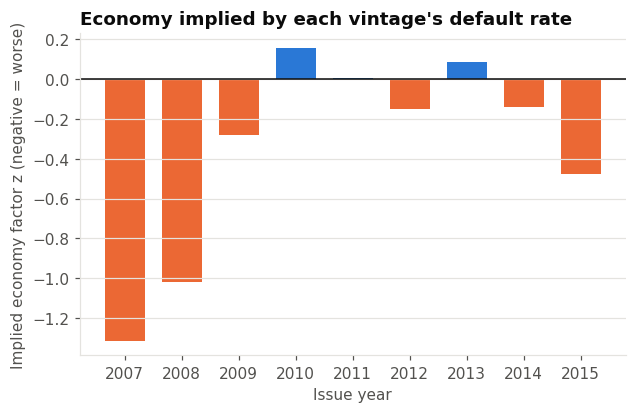

,loans,observed_dr,mean_pd,implied_z,economy_quantile,return_period_years
issue_year,,,,,,
2007,603,0.2620,0.1896,-1.3132,0.0946,10.5759
2008,2393,0.2073,0.1563,-1.0165,0.1547,6.4641
2009,5281,0.1369,0.1303,-0.2825,0.3888,2.5721
2010,9156,0.1092,0.1230,0.1571,0.5624,NaN
2011,14101,0.1063,0.1139,0.0086,0.5034,NaN
2012,43470,0.1358,0.1353,-0.1496,0.4405,2.2699
2013,100422,0.1233,0.1342,0.0884,0.5352,NaN
2014,162570,0.1373,0.1373,-0.1374,0.4453,2.2455
2015,283026,0.1489,0.1318,-0.4741,0.3177,3.1475


In [3]:
vint = pd.concat(S.values(), ignore_index=True)
vint_pd = cm.predict_pd(vint)
anchor = ST.implied_factor_by_vintage(vint, vint_pd, MC.basel_retail_correlation(MC.annualised_pd(vint_pd, C.TERM_YEARS)))
plots.implied_factor_plot(anchor); plt.show()
anchor

The implied factor also absorbs anything else that moved a vintage's default rate, such as
underwriting changes, and the early vintages are small. Treat it as a rough guide to severity.

Downturn LGD and EAD can be read off the same history: loans that defaulted around the recession
lost more and defaulted earlier.

In [4]:
P.loss_parameters_by_year(hist)

,defaults,ead_ratio,lgd,no_recovery
issue_year,,,,
2007,158,0.6331,0.9259,0.0063
2008,496,0.6564,0.9430,0.0302
2009,723,0.6575,0.9307,0.0138
2010,1000,0.6158,0.9258,0.0030
2011,1499,0.5801,0.9275,0.0120
2012,5903,0.5857,0.9089,0.0181
2013,12378,0.5736,0.8857,0.0763
2014,22315,0.5708,0.8856,0.2464


## 2. Scenarios

In [5]:
scenarios = ST.scenarios_from_config(C.STRESS_SCENARIOS)
pd.DataFrame([{"scenario": s.name, "economy": "average" if s.z is None else f"1 in {s.return_period:g}",
               "z": s.z, "lgd_add": s.lgd_add, "ead_add": s.ead_add, "rho_mult": s.rho_mult,
               "rate_shock": s.rate_shock} for s in scenarios]).set_index("scenario")

,economy,z,lgd_add,ead_add,rho_mult,rate_shock
scenario,,,,,,
Base,average,NaN,0.0000,0.0000,1.0000,0.0000
Mild recession,1 in 10,-1.2816,0.0200,0.0300,1.0000,0.0000
Severe recession,1 in 50,-2.0537,0.0400,0.0600,1.2500,0.0000
Interest rate shock,1 in 5,-0.8416,0.0000,0.0000,1.0000,0.0300


## 3. Expected loss under each scenario

`base_distribution_percentile`: where the scenario's loss would fall in the base-case loss
distribution from notebook 07.

In [6]:
inputs = {s.name: ST.stressed_inputs(port, oot, cm, rho, s) for s in scenarios}
table = ST.scenario_table(port, inputs, scenarios)
losses, risk = ST.simulate_scenarios(inputs, exp, C.MC_SIMULATIONS, C.MC_SEED, C.VAR_LEVELS, C.ES_LEVELS)
table["base_distribution_percentile"] = [(losses["Base"] <= v).mean() for v in table["expected_loss"]]
table

,economy,z,mean_pd,expected_defaults,ead,expected_loss,el_rate,vs_base,base_distribution_percentile
Base,average,None,0.1318,37304.3673,2042687576.8913,230221977.6046,0.0635,1.0000,0.5565
Mild recession,1 in 10,-1.2816,0.1972,55820.7245,2151416600.8913,373867582.3653,0.1032,1.6239,0.9318
Severe recession,1 in 50,-2.0537,0.2702,76486.1920,2260145624.8913,554269324.6283,0.1529,2.4075,0.9968
Interest rate shock,1 in 5,-0.8416,0.1705,48264.4372,2042687576.8913,299435794.7085,0.0826,1.3006,0.8030


## 4. Stressed loss distributions

Each scenario's PDs, LGD, EAD and correlation as the starting point, with the economy still
uncertain from there: "how bad could it get from here?" (% of funded amount). All scenarios use the
same random draws, so the base case is exactly notebook 07's result and the differences are pure
scenario effects. 20,000 scenarios each takes about two minutes.

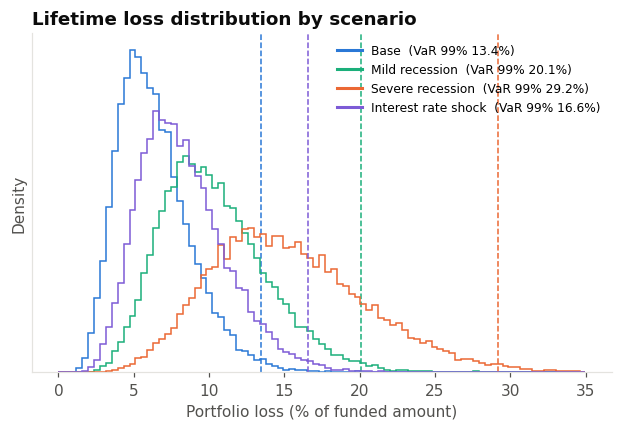

,expected_loss,std,var_0.95,var_0.99,es_0.975,es_0.99
Base,6.3610,2.4264,10.8740,13.4487,13.6084,15.0439
Mild recession,10.3279,3.4921,16.7096,20.0800,20.2245,22.0104
Severe recession,15.3106,5.1428,24.6322,29.1581,29.2943,31.5782
Interest rate shock,8.2723,2.9224,13.6522,16.5806,16.7251,18.3073


In [7]:
plots.stress_distributions({k: v / exp * 100 for k, v in losses.items()}); plt.show()
risk

## 5. Interest rate shock: which channel matters?

The scorecard sees a rate rise through debt-to-income: extra interest on each borrower's revolving
balance. LendingClub loans themselves are fixed-rate.

In [8]:
rate = next(s for s in scenarios if s.rate_shock)
print((ST.apply_rate_shock(oot, rate.rate_shock)["dti"] - oot["dti"]).describe(percentiles=[0.5, 0.9]))
pd.Series({"Base": table.loc["Base", "el_rate"],
           "Payment channel only": ST.el_rate(port, oot, cm, rho, ST.Scenario("p", rate_shock=rate.rate_shock)),
           "Economy only": ST.el_rate(port, oot, cm, rho, ST.Scenario("e", economy_quantile=rate.economy_quantile)),
           "Both (scenario)": table.loc[rate.name, "el_rate"]}, name="el_rate")

count   283024.0000
mean         0.6901
std          0.6577
min          0.0000
50%          0.5410
90%          1.3479
max         49.2017
Name: dti, dtype: float64


Base                   0.0635
Payment channel only   0.0639
Economy only           0.0821
Both (scenario)        0.0826
Name: el_rate, dtype: float64

## 6. Portfolio vulnerability

Severe recession against the base case: which segments' losses rise most, and who carries the
extra loss?

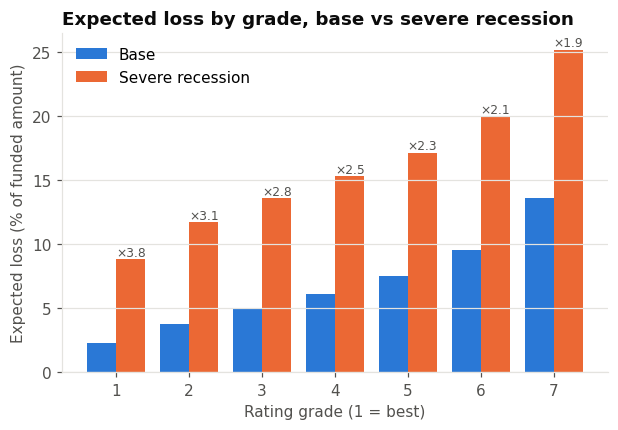

,exposure_share,el_rate_base,el_rate_stress,multiple,share_of_increase
grade,,,,,
1,0.1665,0.0230,0.0881,3.8264,0.1212
2,0.1653,0.0375,0.1170,3.1233,0.1470
3,0.1554,0.0493,0.1361,2.7616,0.1509
4,0.1419,0.0611,0.1531,2.5043,0.1460
5,0.1344,0.0748,0.1713,2.2914,0.1451
6,0.1249,0.0955,0.1996,2.0899,0.1454
7,0.1116,0.1361,0.2518,1.8503,0.1445


In [9]:
vul = {by: ST.segment_vulnerability(port, inputs["Base"], inputs["Severe recession"], by)
       for by in ("grade", "purpose", "size_band")}
plots.vulnerability_plot(vul["grade"]); plt.show()
vul["grade"]

In [10]:
vul["purpose"].sort_values("exposure_share", ascending=False).head(8)

,exposure_share,el_rate_base,el_rate_stress,multiple,share_of_increase
purpose,,,,,
debt_consolidation,0.5896,0.0688,0.1609,2.3379,0.6073
credit_card,0.2701,0.0514,0.1354,2.6342,0.2538
home_improvement,0.0572,0.0460,0.1266,2.7490,0.0515
other,0.0353,0.0859,0.1841,2.1442,0.0388
major_purchase,0.0151,0.0418,0.1195,2.8562,0.0131
small_business,0.0091,0.1132,0.2202,1.9451,0.0108
medical,0.0064,0.0809,0.1776,2.1939,0.0069
car,0.0064,0.0479,0.1294,2.7020,0.0058


In [11]:
vul["size_band"]

,exposure_share,el_rate_base,el_rate_stress,multiple,share_of_increase
size_band,,,,,
≤ $5k,0.0469,0.0731,0.1671,2.2858,0.0493
$5k–10k,0.2155,0.0725,0.1658,2.2868,0.2249
$10k–15k,0.2053,0.0687,0.1602,2.3330,0.2102
$15k–25k,0.3287,0.0606,0.1487,2.4556,0.3240
> $25k,0.2037,0.0514,0.1355,2.6368,0.1916


## 7. Sensitivity to the assumptions

Each assumption of the severe scenario moved to a low and a high value, one at a time. `pd_scale`
1.13 removes the 2015 calibration gap found in notebook 05.

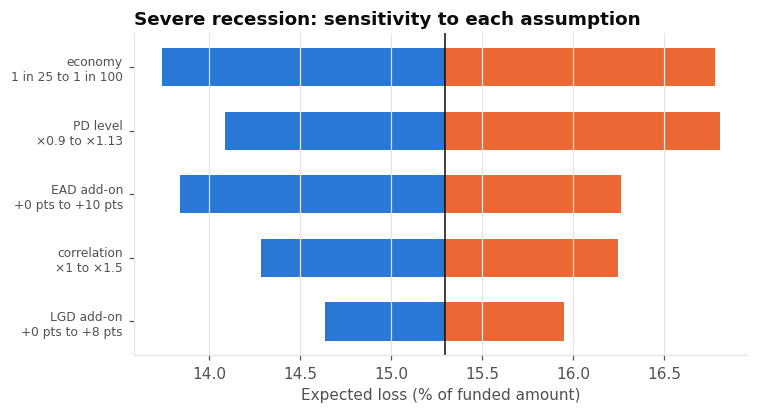

,central,low,high,el_rate_low,el_rate_high,el_rate_central,range
assumption,,,,,,,
economy_quantile,0.0200,0.0400,0.0100,0.1374,0.1678,0.1529,0.0304
pd_scale,1.0000,0.9000,1.1300,0.1409,0.1681,0.1529,0.0272
ead_add,0.0600,0.0000,0.1000,0.1384,0.1626,0.1529,0.0243
rho_mult,1.2500,1.0000,1.5000,0.1428,0.1625,0.1529,0.0196
lgd_add,0.0400,0.0000,0.0800,0.1464,0.1595,0.1529,0.0131


In [12]:
severe = next(s for s in scenarios if s.name == "Severe recession")
sens = ST.sensitivity(port, oot, cm, rho, severe, C.STRESS_SENSITIVITY)
plots.tornado_plot(sens); plt.show()
sens

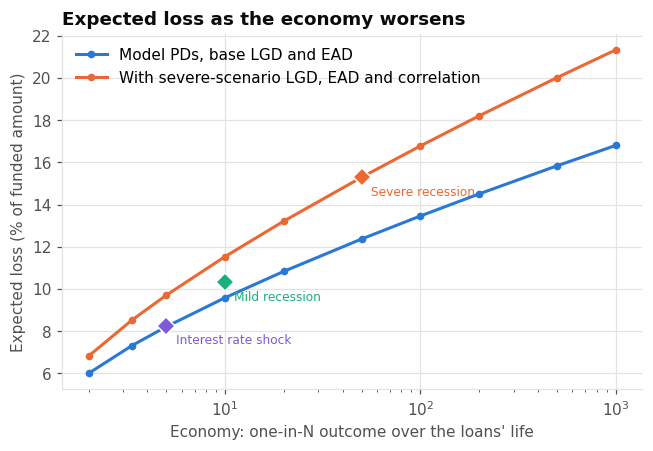

,"Model PDs, base LGD and EAD","With severe-scenario LGD, EAD and correlation"
economy_quantile,,
0.5000,0.0600,0.0682
0.3000,0.0732,0.0853
0.2000,0.0821,0.0971
0.1000,0.0959,0.1154
0.0500,0.1084,0.1322
0.0200,0.1237,0.1529
0.0100,0.1346,0.1678
0.0050,0.1451,0.1821
0.0020,0.1583,0.2001


In [13]:
curves = {"Model PDs, base LGD and EAD": ST.economy_curve(port, rho, C.STRESS_CURVE_QUANTILES),
          "With severe-scenario LGD, EAD and correlation": ST.economy_curve(
              port, rho, C.STRESS_CURVE_QUANTILES, severe.lgd_add, severe.ead_add, severe.rho_mult)}
points = {s.name: (s.economy_quantile, table.loc[s.name, "el_rate"]) for s in scenarios if s.z is not None}
plots.economy_curve_plot(curves, points); plt.show()
pd.DataFrame(curves)

## 8. Reverse stress test

How rare an economy would have to be for lifetime losses to reach each level?

In [14]:
pd.concat({"base LGD and EAD": ST.reverse_stress(port, rho, C.REVERSE_STRESS_THRESHOLDS),
           "downturn LGD, EAD and correlation": ST.reverse_stress(
               port, rho, C.REVERSE_STRESS_THRESHOLDS, severe.lgd_add, severe.ead_add, severe.rho_mult)}, axis=1)

base LGD and EAD                                       \
                              z economy_quantile return_period_years   
loss_threshold                                                         
0.0800                  -0.7684           0.2211              4.5221   
0.1000                  -1.4051           0.0800             12.4995   
0.1500                  -2.6897           0.0036            279.6625   
0.2000                  -3.7565           0.0001          11605.6805   

               downturn LGD, EAD and correlation                   \
                                               z economy_quantile   
loss_threshold                                                      
0.0800                                   -0.3717           0.3551   
0.1000                                   -0.9157           0.1799   
0.1500                                   -1.9981           0.0229   
0.2000                                   -2.8760           0.0020   

                                    
               return_period_years  
loss_threshold                      
0.0800                      2.8163  
0.1000                      5.5580  
0.1500                     43.7623  
0.2000                    496.5080

## Findings
- LendingClub's 2007 and 2008 loans, which ran through the 2008–09 recession, imply 1-in-10.6 and
  1-in-6.5 economies, so the mild scenario (1-in-10) matches the worst conditions in the data and the
  severe one (1-in-50) goes beyond them. 2015 implies a 1-in-3.1 economy, the drift seen in notebook 05.
- Lifetime expected loss rises from 6.35% of funded amount to 10.32% in a mild recession (×1.6) and
  15.29% in a severe one (×2.4, $554m against $230m). The severe loss lies beyond the base 99% VaR
  (13.45%), at the 99.7th percentile of the base distribution.
- Starting from each scenario, the 99% VaR rises from 13.4% (base) to 20.1% (mild) and 29.2% (severe).
- A 300bp rate rise adds only 0.54 points to the median borrower's debt-to-income and moves expected
  loss from 6.35% to 6.39%. Almost all of the rate scenario's 8.26% comes from the slower economy.
- The safest grade's expected loss rises 3.8 times in a severe recession against 1.9 times for the
  riskiest, and every grade carries 12–15% of the extra loss.
- Severity and the PD level matter most: removing the calibration gap adds as much loss as moving
  from a 1-in-50 to a 1-in-100 economy. LGD matters least, because it is already near 100%.
- Lifetime losses reach 10% in a 1-in-12 economy, or 1-in-6 with downturn LGD, EAD and correlation.